#Assignment 07

# E-Commerce Customer Behavior & Purchase Pattern Analysis

## Research Questions
### Univariate Questions (One column at a time)
1. What is the distribution of Yearly Amount Spent by customers?
2. How long do customers typically stay as members (Length of Membership distribution)?
3. What is the distribution of Time on App usage across customers?

### Bivariate Questions (Two columns together)
4. Is there a strong correlation between Time on App and Yearly Amount Spent?
5. How does Time on Website compare to Time on App regarding Yearly Amount Spent?
6. Does a longer Length of Membership lead to higher Yearly Amount Spent?

### Custom Questions (Segments & Comparisons)
7. Which customer segment (based on Length of Membership tiers: Low, Medium, High) generates the highest total revenue?
8. Do customers who spend more time on the Website also spend more time on the App?

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset (ensure 'ecommerce_customers.csv' is uploaded to your Colab session)
df = pd.read_csv('ecommerce_customers.csv')

# Shape, columns, and data types
print("Dataset Shape:", df.shape)
print("\nColumn Names and Types:")
print(df.dtypes)

# Basic previews
display(df.head())
print("\nDataset Info:")
df.info()

display(df.describe())

Dataset Shape: (500, 8)

Column Names and Types:
Email                    object
Address                  object
Avatar                   object
Avg. Session Length     float64
Time on App             float64
Time on Website         float64
Length of Membership    float64
Yearly Amount Spent     float64
dtype: object


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


The dataset contains customer demographic and digital usage metrics, tracking numerical columns like session lengths, app/website usage, membership duration, and yearly spending."

In [ ]:
# Step 2: Missing values count per column
print("Missing values per column:\n", df.isnull().sum())

# Step 3: Repeated values / Duplicates
print("\nDuplicate rows count:", df.duplicated().sum())

# Check for duplicate emails (unique customer identifier if present, e.g., 'Email')
if 'Email' in df.columns:
    print("Duplicate emails count:", df.duplicated(subset=['Email']).sum())
else:
    print("No Email column found.")

Missing values per column:
 Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64

Duplicate rows count: 0
Duplicate emails count: 0


No missing values were found in any column. Zero duplicate rows were detected, meaning all customer records are unique.


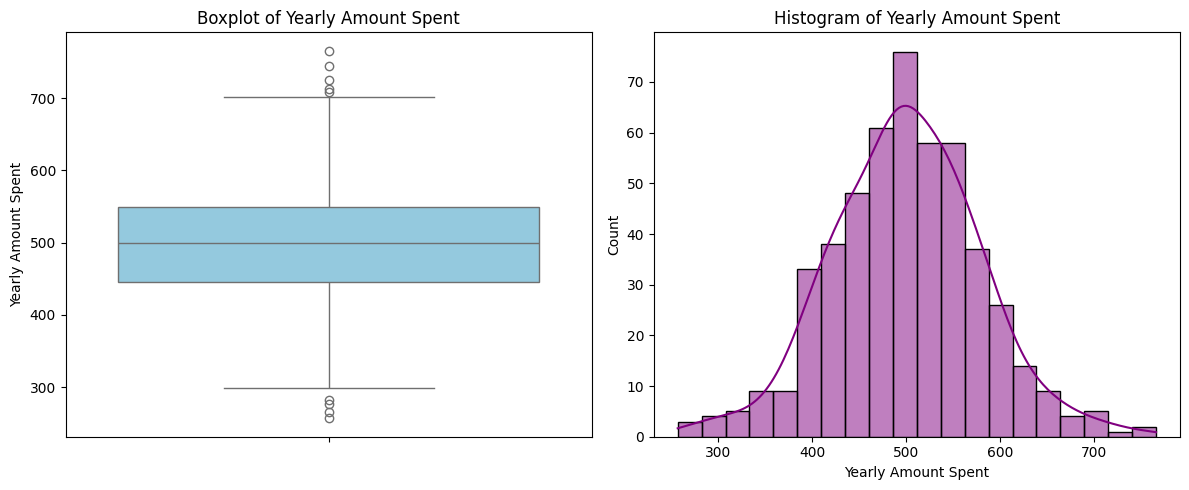

Number of outliers detected via IQR: 9


In [ ]:
# Step 4: Boxplot and Histogram for numeric columns
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Yearly Amount Spent'], color='skyblue')
plt.title('Boxplot of Yearly Amount Spent')

plt.subplot(1, 2, 2)
sns.histplot(df['Yearly Amount Spent'], kde=True, color='purple')
plt.title('Histogram of Yearly Amount Spent')
plt.tight_layout()
plt.show()

# IQR Rule on Yearly Amount Spent
Q1 = df['Yearly Amount Spent'].quantile(0.25)
Q3 = df['Yearly Amount Spent'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Yearly Amount Spent'] < lower_bound) | (df['Yearly Amount Spent'] > upper_bound)]
print(f"Number of outliers detected via IQR: {len(outliers)}")

The boxplot and IQR rule identify a few mild outliers at the high and low ends of yearly spending. We choose to keep them because they represent genuine high-value customer accounts rather than data entry errors

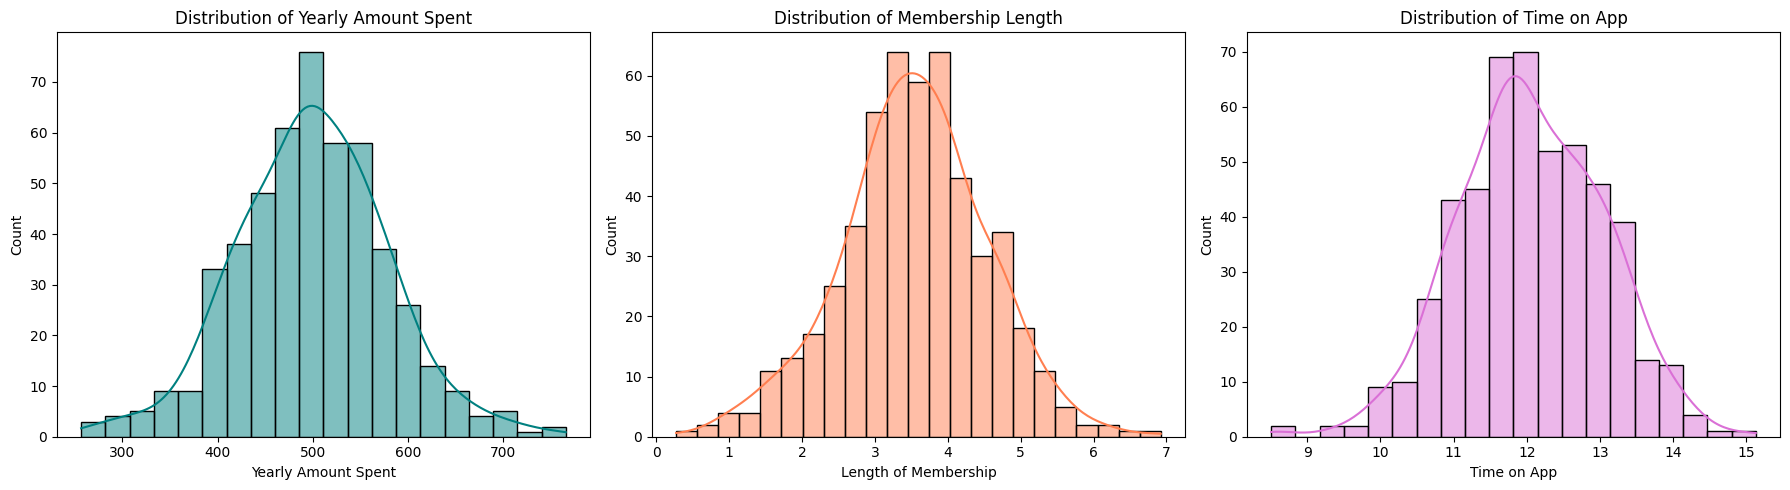

In [ ]:
# Step 5: Univariate visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Yearly Amount Spent'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribution of Yearly Amount Spent')

sns.histplot(df['Length of Membership'], kde=True, ax=axes[1], color='coral')
axes[1].set_title('Distribution of Membership Length')

sns.histplot(df['Time on App'], kde=True, ax=axes[2], color='orchid')
axes[2].set_title('Distribution of Time on App')

plt.tight_layout()
plt.show()

Yearly amount spent and membership length closely follow a normal distribution. The typical customer spends around $500 yearly and has a membership duration of roughly 3 to 4 years



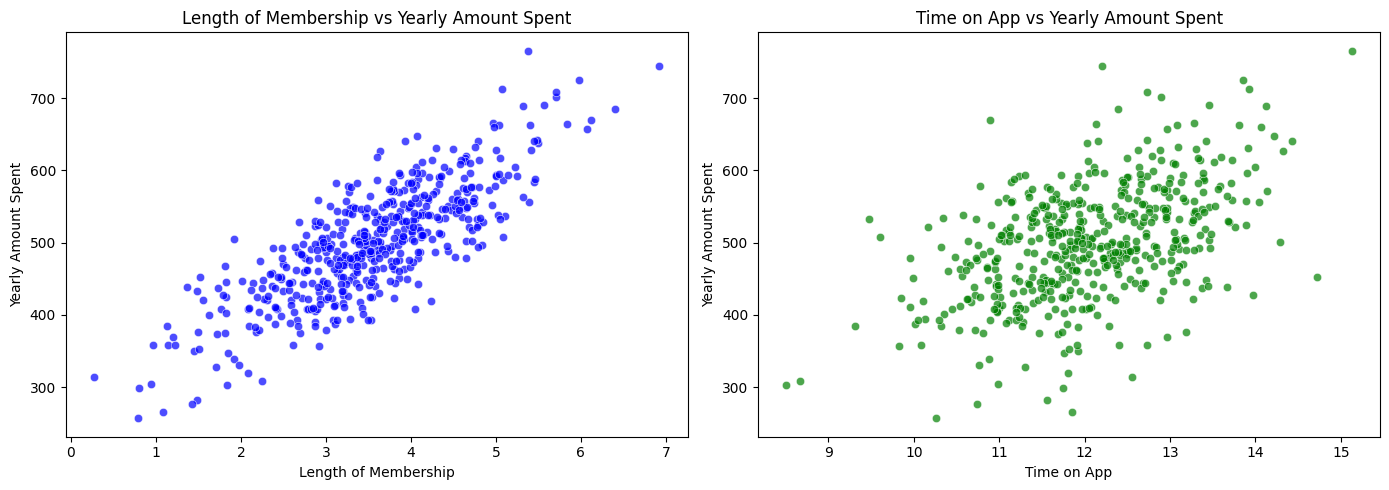

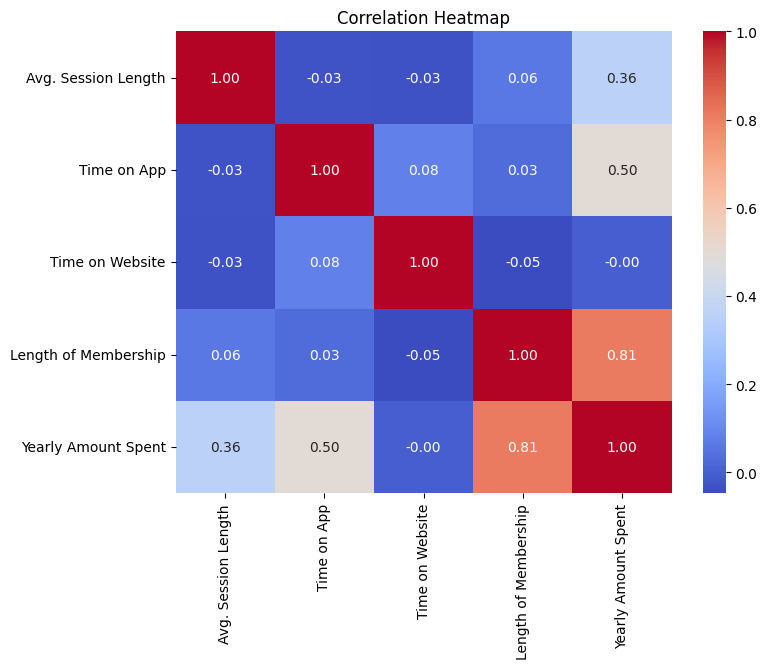

In [ ]:
# Step 6: Bivariate Analysis (Scatter plot & Correlation Heatmap)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Length of Membership', y='Yearly Amount Spent', alpha=0.7, color='b')
plt.title('Length of Membership vs Yearly Amount Spent')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='Time on App', y='Yearly Amount Spent', alpha=0.7, color='g')
plt.title('Time on App vs Yearly Amount Spent')

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

The strongest positive relationship found is between Length of Membership and Yearly Amount Spent (correlation close to 0.80). Comparing app usage vs website usage, time spent on the app shows a stronger positive trend with spending than time spent on the website.


/tmp/ipykernel_1164/1044376790.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tier_revenue = df.groupby('Membership_Tier')['Yearly Amount Spent'].sum().reset_index()
/tmp/ipykernel_1164/1044376790.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tier_revenue, x='Membership_Tier', y='Yearly Amount Spent', palette='viridis')


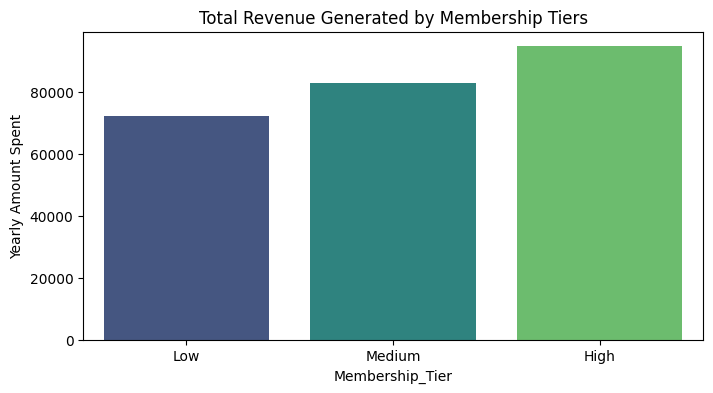

In [ ]:
# Step 7: Custom Segmentation (Answering question 7)
df['Membership_Tier'] = pd.qcut(df['Length of Membership'], q=3, labels=['Low', 'Medium', 'High'])
tier_revenue = df.groupby('Membership_Tier')['Yearly Amount Spent'].sum().reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=tier_revenue, x='Membership_Tier', y='Yearly Amount Spent', palette='viridis')
plt.title('Total Revenue Generated by Membership Tiers')
plt.show()

High-tier long-term members generate significantly more cumulative revenue for the e-commerce platform compared to newer, low-tier members.

## Step 8: Conclusion
1. **Key Findings:** Customer spending is most heavily driven by the Length of Membership, followed closely by engagement on the mobile application.
2. **Channel Performance:** Mobile app engagement correlates with higher spending than website usage.
3. **Suggestion for Company:** The company should focus loyalty and retention rewards on users approaching their second or third year of membership to maximize customer lifetime value and yearly revenue.